# Part 01 -Import Required Libraries

In [1]:

import os
import warnings
import shutil
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

warnings.filterwarnings('ignore')

print("Libraries imported successfully!")


Libraries imported successfully!


# Part 02-Upload processed files to Google Colab

In [2]:

from google.colab import files

uploaded = files.upload()


Saving X_test.csv to X_test.csv
Saving X_train.csv to X_train.csv
Saving y_test.csv to y_test.csv
Saving y_train.csv to y_train.csv


# Part 03 -Load the processed datasets

In [3]:

# Load training and testing datasets

X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')

y_train = pd.read_csv('y_train.csv')
y_test = pd.read_csv('y_test.csv')

# Remove unnecessary index columns, if present
X_train = X_train.loc[:, ~X_train.columns.str.startswith('Unnamed:')]
X_test = X_test.loc[:, ~X_test.columns.str.startswith('Unnamed:')]

y_train = y_train.loc[:, ~y_train.columns.str.startswith('Unnamed:')]
y_test = y_test.loc[:, ~y_test.columns.str.startswith('Unnamed:')]

# Convert target DataFrames into Series
y_train = y_train.iloc[:, 0]
y_test = y_test.iloc[:, 0]

# Display dataset dimensions
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training data: (800, 25)
Testing data: (200, 25)
Training target: (800,)
Testing target: (200,)

Training target distribution:
no_show
0    404
1    396
Name: count, dtype: int64

Testing target distribution:
no_show
0    101
1     99
Name: count, dtype: int64


# Part 04-Initialize the four machine learning models

In [4]:

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),

    'Decision Tree': DecisionTreeClassifier(random_state=42),

    'Random Forest': RandomForestClassifier(random_state=42),

    'SVM': SVC(probability=True, random_state=42)
}

print("Four machine learning models initialized!")


Four machine learning models initialized!


# Part 05-Define hyperparameter grids

In [5]:

param_grids = {
    'Logistic Regression': {
        'C': [0.01, 0.1, 1, 10],
        'solver': ['lbfgs']
    },

    'Decision Tree': {
        'max_depth': [None, 3, 5, 10],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    },

    'Random Forest': {
        'n_estimators': [100, 200],
        'max_depth': [None, 5, 10],
        'min_samples_split': [2, 5],
        'min_samples_leaf': [1, 2]
    },

    'SVM': [
        {
            'kernel': ['linear'],
            'C': [0.1, 1, 10]
        },
        {
            'kernel': ['rbf'],
            'C': [0.1, 1, 10],
            'gamma': ['scale', 'auto']
        }
    ]
}

print("Hyperparameter grids defined!")


Hyperparameter grids defined!


# Part 06-Train and tune all four models

In [6]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best_models = {}
tuning_results = []

for model_name, model in models.items():

    print("\nTraining:", model_name)

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[model_name],
        scoring='f1',
        cv=cv,
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    best_models[model_name] = grid_search.best_estimator_

    tuning_results.append({
        'Model': model_name,
        'Best_CV_F1': grid_search.best_score_,
        'Best_Parameters': grid_search.best_params_
    })

    print("Best parameters:", grid_search.best_params_)
    print("Best CV F1-score:", round(grid_search.best_score_, 4))

tuning_df = pd.DataFrame(tuning_results)

print("\nHyperparameter tuning completed!")
display(tuning_df)



Training: Logistic Regression
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'C': 0.1, 'solver': 'lbfgs'}
Best CV F1-score: 0.6001

Training: Decision Tree
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV F1-score: 0.5374

Training: Random Forest
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best CV F1-score: 0.582

Training: SVM
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best parameters: {'C': 1, 'gamma': 'auto', 'kernel': 'rbf'}
Best CV F1-score: 0.6019

Hyperparameter tuning completed!


,Model,Best_CV_F1,Best_Parameters
0,Logistic Regression,0.600052,"{'C': 0.1, 'solver': 'lbfgs'}"
1,Decision Tree,0.537377,"{'max_depth': 3, 'min_samples_leaf': 1, 'min_s..."
2,Random Forest,0.582048,"{'max_depth': 10, 'min_samples_leaf': 1, 'min_..."
3,SVM,0.601943,"{'C': 1, 'gamma': 'auto', 'kernel': 'rbf'}"


#Part 07-Evaluate model performance

In [7]:

evaluation_results = []

for model_name, model in best_models.items():

    y_pred = model.predict(X_test)

    y_probability = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_probability)

    evaluation_results.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1_Score': f1,
        'ROC_AUC': roc_auc
    })

    print("\n", "=" * 50)
    print(model_name)
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

comparison_df = pd.DataFrame(evaluation_results)

comparison_df = comparison_df.sort_values(
    by='F1_Score',
    ascending=False
)

display(comparison_df.round(4))



Logistic Regression
              precision    recall  f1-score   support

           0       0.61      0.62      0.62       101
           1       0.61      0.60      0.60        99

    accuracy                           0.61       200
   macro avg       0.61      0.61      0.61       200
weighted avg       0.61      0.61      0.61       200


Decision Tree
              precision    recall  f1-score   support

           0       0.59      0.69      0.64       101
           1       0.62      0.51      0.56        99

    accuracy                           0.60       200
   macro avg       0.60      0.60      0.60       200
weighted avg       0.60      0.60      0.60       200


Random Forest
              precision    recall  f1-score   support

           0       0.64      0.64      0.64       101
           1       0.64      0.64      0.64        99

    accuracy                           0.64       200
   macro avg       0.64      0.64      0.64       200
weighted avg       0.64

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
2,Random Forest,0.640,0.6364,0.6364,0.6364,0.6672
0,Logistic Regression,0.610,0.6082,0.5960,0.6020,0.6336
3,SVM,0.595,0.5978,0.5556,0.5759,0.6485
1,Decision Tree,0.600,0.6173,0.5051,0.5556,0.6581


# Part 08-Visualize the model comparison

<Figure size 1000x600 with 0 Axes>

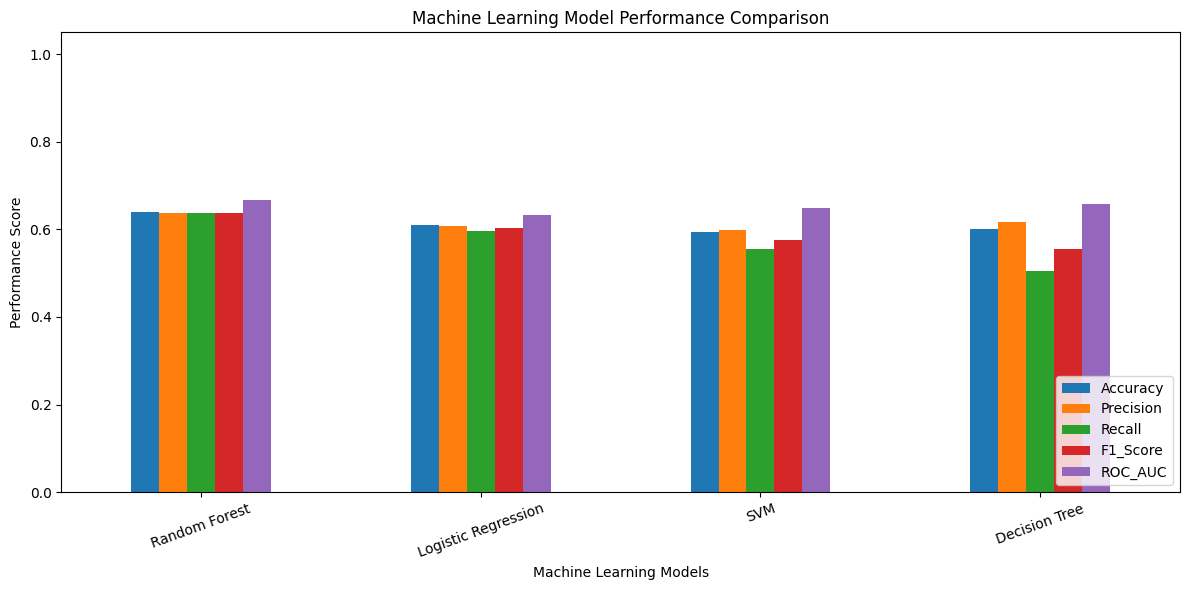

In [8]:

plt.figure(figsize=(10, 6))

comparison_plot = comparison_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC']
]

comparison_plot.plot(kind='bar', figsize=(12, 6))

plt.title('Machine Learning Model Performance Comparison')
plt.ylabel('Performance Score')
plt.xlabel('Machine Learning Models')
plt.xticks(rotation=20)
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


# Part 09-Generate confusion matrices

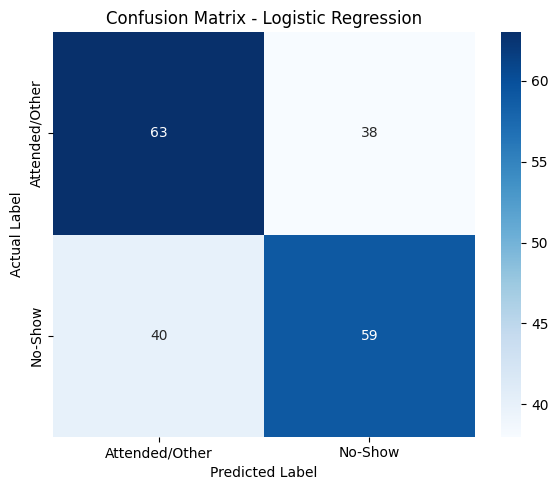

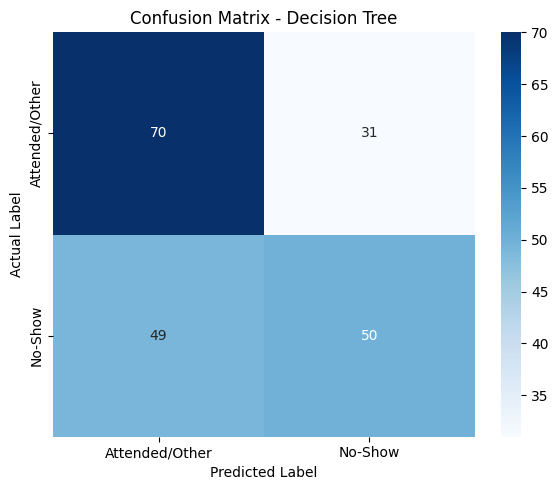

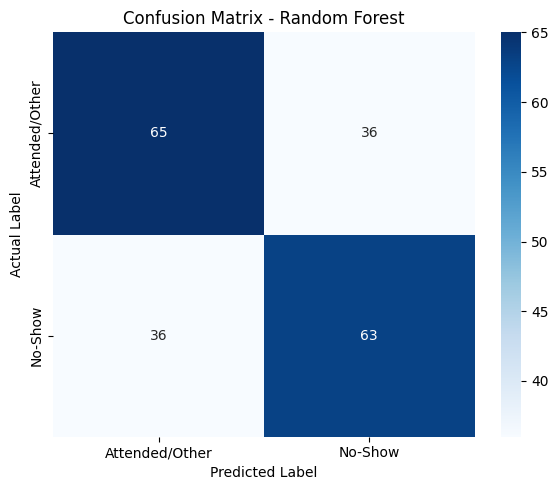

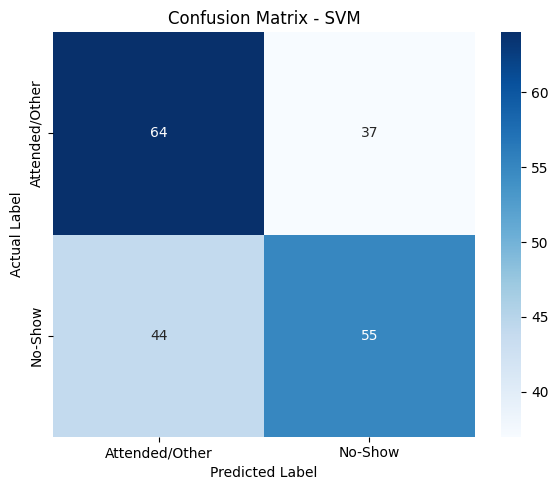

In [9]:

for model_name, model in best_models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Attended/Other', 'No-Show'],
        yticklabels=['Attended/Other', 'No-Show']
    )

    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')
    plt.tight_layout()
    plt.show()


# Part 10-Generate ROC curves

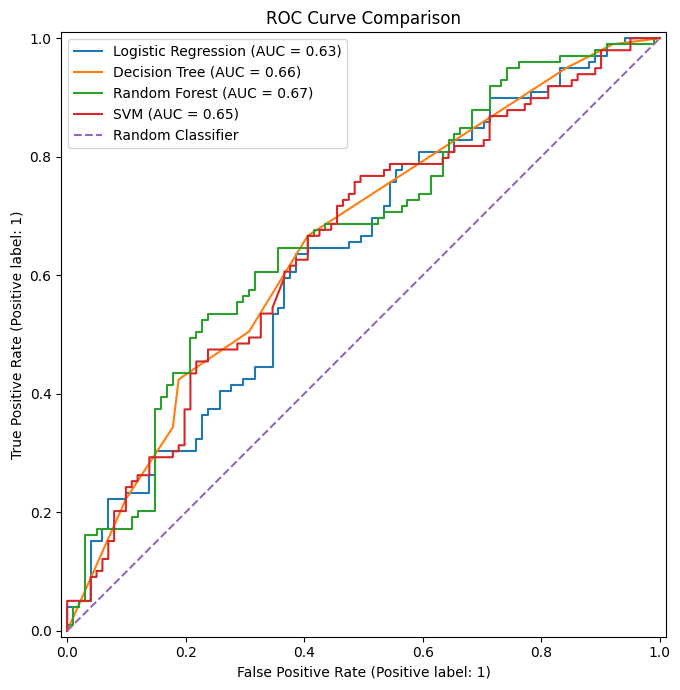

In [10]:

plt.figure(figsize=(9, 7))

for model_name, model in best_models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=model_name,
        ax=plt.gca()
    )

plt.title('ROC Curve Comparison')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.legend()
plt.tight_layout()
plt.show()


# Part 11-Create folders and save the trained models

In [11]:

# Create project output folders
project_folder = '/content/smartcare-hospital-ai'

models_folder = os.path.join(project_folder, 'models')
tables_folder = os.path.join(project_folder, 'reports', 'tables')
evaluation_folder = os.path.join(
    project_folder, 'reports', 'figures', 'evaluation'
)

os.makedirs(models_folder, exist_ok=True)
os.makedirs(tables_folder, exist_ok=True)
os.makedirs(evaluation_folder, exist_ok=True)

# Save all four tuned models
model_filenames = {
    'Logistic Regression': 'logistic_regression_model.joblib',
    'Decision Tree': 'decision_tree_model.joblib',
    'Random Forest': 'random_forest_model.joblib',
    'SVM': 'svm_model.joblib'
}

for model_name, model in best_models.items():

    file_path = os.path.join(
        models_folder,
        model_filenames[model_name]
    )

    joblib.dump(model, file_path)

    print("Saved:", file_path)

# Select best model using cross-validation F1-score
best_model_name = tuning_df.sort_values(
    by='Best_CV_F1',
    ascending=False
).iloc[0]['Model']

best_model = best_models[best_model_name]

joblib.dump(
    best_model,
    os.path.join(models_folder, 'best_model.joblib')
)

print("\nBest model:", best_model_name)
print("Best model saved successfully!")


Saved: /content/smartcare-hospital-ai/models/logistic_regression_model.joblib
Saved: /content/smartcare-hospital-ai/models/decision_tree_model.joblib
Saved: /content/smartcare-hospital-ai/models/random_forest_model.joblib
Saved: /content/smartcare-hospital-ai/models/svm_model.joblib

Best model: SVM
Best model saved successfully!


# Part 12-Save the model comparison tables

In [12]:

# Save test performance comparison
comparison_df.to_csv(
    os.path.join(tables_folder, 'model_comparison.csv'),
    index=False
)

# Save hyperparameter tuning results
tuning_df.to_csv(
    os.path.join(tables_folder, 'hyperparameter_tuning_results.csv'),
    index=False
)

print("Model comparison and tuning tables saved!")


Model comparison and tuning tables saved!


# Part 13-Save the evaluation charts as PNG images

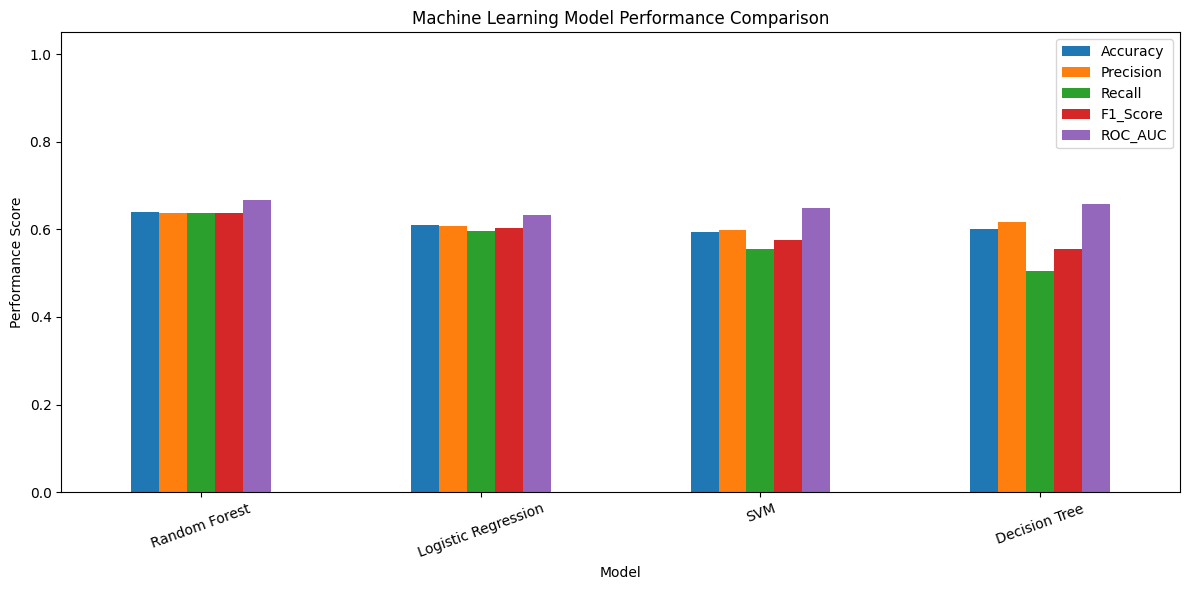

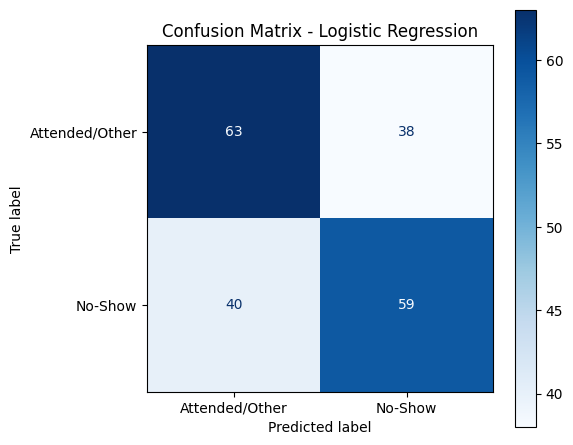

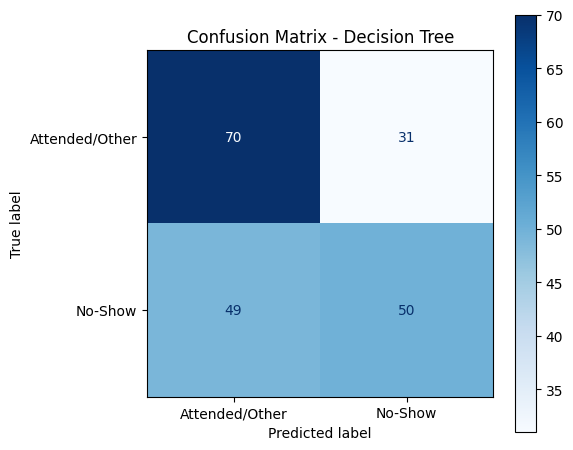

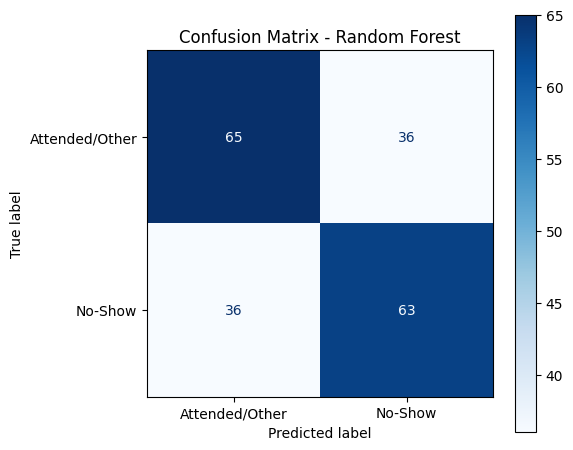

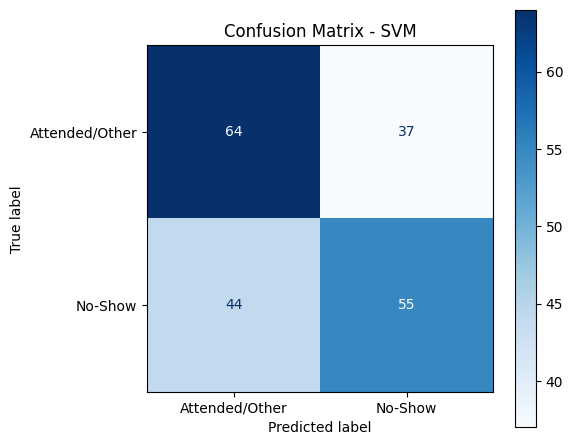

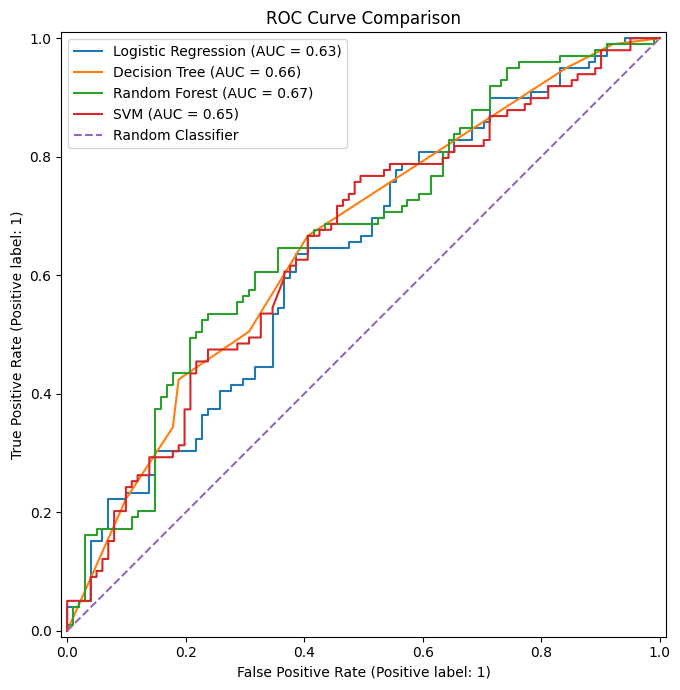

All evaluation charts saved!


In [13]:

# Save model performance comparison chart
plt.figure(figsize=(12, 6))

comparison_plot = comparison_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC']
]

comparison_plot.plot(kind='bar', ax=plt.gca())

plt.title('Machine Learning Model Performance Comparison')
plt.ylabel('Performance Score')
plt.xlabel('Model')
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    os.path.join(evaluation_folder, 'model_comparison.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

# Save confusion matrices
for model_name, model in best_models.items():

    y_pred = model.predict(X_test)

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=['Attended/Other', 'No-Show'],
        cmap='Blues',
        ax=ax
    )

    ax.set_title(f'Confusion Matrix - {model_name}')
    fig.tight_layout()

    safe_name = model_name.lower().replace(' ', '_')

    fig.savefig(
        os.path.join(
            evaluation_folder,
            f'{safe_name}_confusion_matrix.png'
        ),
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()
    plt.close()

# Save combined ROC curve
fig, ax = plt.subplots(figsize=(9, 7))

for model_name, model in best_models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=model_name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
ax.set_title('ROC Curve Comparison')
ax.legend()
fig.tight_layout()

fig.savefig(
    os.path.join(evaluation_folder, 'roc_curve_comparison.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

print("All evaluation charts saved!")


# Part 14-Download all Task 05 files

In [14]:

from google.colab import files

zip_path = shutil.make_archive(
    '/content/Task05_ML_Results',
    'zip',
    project_folder
)

print("ZIP file created successfully!")

files.download(zip_path)


ZIP file created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>